# TP3 · Paso 4 — Optimización del sistema

A partir del diagnóstico del paso 3 (cohorte `cloud_marketplace` y reservas únicas concentran los errores; *high variance* con validación estancada) evaluamos estrategias de mejora. **Todas** se comparan contra el baseline con **el mismo esquema**: CV 5-fold estratificada por grupos sobre train, predicciones OOF, y reportamos:

- **Balanced Accuracy** (umbral 0.5) y **ROC-AUC** globales;
- **Balanced Accuracy en `cloud_marketplace`** (la cohorte priorizada en 3.3).

| # | Estrategia | Tipo (consigna) | Motivación (paso 3) |
|---|---|---|---|
| E1 | Features nuevas | Feature engineering | falta información en X |
| E2 | Ponderación de lotes duplicados | Data-centered (selección/peso de ejemplos) | errores en reservas únicas; los lotes ya se predicen bien |
| E3 | Búsqueda de hiperparámetros | Hyperparameter optimization | brecha train-val ≈ 0.10 |
| E4 | Votación RF + HGB | Ensemble / model selection | reducir varianza |
| E5 | Umbral óptimo | Ajuste de decisión | 39 % de errores en zona dudosa |
| E6 | Memoria de reservas ya vistas | Data-centered (uso de duplicados) | 33 % de duplicados con etiqueta 99 % consistente |

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict

import tp3_comun as C

X_train, y_train = C.cargar_split("train")
Xf_train = C.agregar_features(X_train)
grupos = C.firma_duplicados(X_train)
tam_lote = pd.Series(grupos).map(pd.Series(grupos).value_counts()).values
es_cm = (X_train["client_type"] == "cloud_marketplace").values
base = joblib.load(C.RESULTADOS / "paso2_baseline.joblib")
HP_BASE = {k.split("__")[1]: v for k, v in base["modelo"].get_params().items()
           if k.startswith("histgradientboostingclassifier__") and k.split("__")[1] in
           ("learning_rate", "max_leaf_nodes", "max_iter", "class_weight", "random_state")}
print("HP baseline:", HP_BASE)

resultados, probas = {}, {}

def evaluar(nombre, modelo, X, peso=None, umbral=0.5):
    # OOF con CV por grupos -> métricas globales y en cloud_marketplace
    t = time.time()
    params = {f"{modelo.steps[-1][0]}__sample_weight": peso} if peso is not None else None
    p = cross_val_predict(modelo, X, y_train, groups=grupos, cv=C.crear_cv("grupo"),
                          method="predict_proba", n_jobs=5, params=params)[:, 1]
    probas[nombre] = p
    resultados[nombre] = {
        "BA": balanced_accuracy_score(y_train, p >= umbral), "AUC": roc_auc_score(y_train, p),
        "BA_cloud_mkt": balanced_accuracy_score(y_train[es_cm], p[es_cm] >= umbral),
        "BA_resto": balanced_accuracy_score(y_train[~es_cm], p[~es_cm] >= umbral),
        "seg": time.time() - t}
    r = resultados[nombre]
    print(f"{nombre:38s} BA={r['BA']:.4f} AUC={r['AUC']:.4f} BA_cloud_mkt={r['BA_cloud_mkt']:.4f}")
    return p

def hgb(set_nombre, **hp):
    return C.pipeline(set_nombre, HistGradientBoostingClassifier(
        categorical_features=C.idx_categoricas(set_nombre), **{**HP_BASE, **hp}))

_ = evaluar("E0 · Baseline (HGB, 28 originales)", base["modelo"], X_train)

HP baseline: {'class_weight': 'balanced', 'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 127, 'random_state': 42}


E0 · Baseline (HGB, 28 originales)     BA=0.8524 AUC=0.9389 BA_cloud_mkt=0.7774


## E1 · Feature engineering

Features nuevas definidas en el paso 1 (`agregar_features`): costo total, costo por proceso, GPU cambiada, día de la semana y del año, indicadores de faltantes, ratio de cancelaciones previas, y los **ids de agente/organización como categorías** (en el baseline eran un número sin orden real). La hipótesis del paso 3: dar al modelo más información sobre el agente/lote y el valor económico debería ayudar en `cloud_marketplace`.

In [2]:
_ = evaluar("E1 · + Feature engineering", hgb("FE"), Xf_train)

E1 · + Feature engineering             BA=0.8513 AUC=0.9376 BA_cloud_mkt=0.7814


## E2 · Ponderación de ejemplos (lotes de duplicados)

El 26 % de train son lotes de 6+ reservas idénticas que el modelo ya predice casi perfecto (BA 0.93), mientras que el 73 % de los errores está en reservas únicas. Con peso 1 por fila, un lote de 100 copias "vale" 100 veces más que una reserva única en la función de pérdida. Probamos dar a cada fila peso $1/\sqrt{n_{lote}}$ (amortigua sin anular) y $1/n_{lote}$ (cada lote pesa como una sola reserva). Los pesos se usan **sólo para entrenar**; la evaluación es sobre las filas reales.

In [3]:
_ = evaluar("E2a · FE + peso 1/sqrt(n_lote)", hgb("FE"), Xf_train, peso=1 / np.sqrt(tam_lote))
_ = evaluar("E2b · FE + peso 1/n_lote", hgb("FE"), Xf_train, peso=1 / tam_lote)

E2a · FE + peso 1/sqrt(n_lote)         BA=0.8533 AUC=0.9404 BA_cloud_mkt=0.7810


E2b · FE + peso 1/n_lote               BA=0.8523 AUC=0.9403 BA_cloud_mkt=0.7788


## E3 · Optimización de hiperparámetros

`RandomizedSearchCV` (25 combinaciones, misma CV por grupos, `refit` por balanced accuracy) sobre HGB con FE y peso $1/\sqrt{n}$. Exploramos capacidad (`max_leaf_nodes`, `max_iter`, `learning_rate`) y regularización (`min_samples_leaf`, `l2_regularization`, `max_features`) para atacar la brecha train–val.

In [4]:
espacio = {
    "histgradientboostingclassifier__learning_rate": loguniform(0.02, 0.15),
    "histgradientboostingclassifier__max_leaf_nodes": randint(31, 256),
    "histgradientboostingclassifier__max_iter": randint(300, 1000),
    "histgradientboostingclassifier__min_samples_leaf": randint(5, 80),
    "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
    "histgradientboostingclassifier__max_features": [0.5, 0.7, 1.0],
}
t = time.time()
busq = RandomizedSearchCV(hgb("FE"), espacio, n_iter=25, scoring=C.SCORING, refit="bal_acc",
                          cv=C.crear_cv("grupo"), n_jobs=5, random_state=C.RANDOM_STATE, return_train_score=True)
busq.fit(Xf_train, y_train, groups=grupos, histgradientboostingclassifier__sample_weight=1 / np.sqrt(tam_lote))
print(f"{time.time()-t:.0f}s")
rs = pd.DataFrame(busq.cv_results_)
cols = [c for c in rs if c.startswith("param_")]
tabla_rs = rs[cols + ["mean_train_bal_acc", "mean_test_bal_acc", "std_test_bal_acc", "mean_test_roc_auc"]]
tabla_rs.columns = [c.replace("param_histgradientboostingclassifier__", "") for c in tabla_rs.columns]
display(tabla_rs.sort_values("mean_test_bal_acc", ascending=False).head(8).round(4))
HP_OPT = {k.split("__")[1]: v for k, v in busq.best_params_.items()}
print("Mejores:", HP_OPT)

280s


,l2_regularization,learning_rate,max_features,max_iter,max_leaf_nodes,min_samples_leaf,mean_train_bal_acc,mean_test_bal_acc,std_test_bal_acc,mean_test_roc_auc
13,0.0046,0.0206,0.5,643,159,12,0.9598,0.8560,0.0051,0.9421
11,0.0200,0.0438,0.7,352,54,30,0.9248,0.8547,0.0046,0.9407
5,0.2975,0.0432,0.5,430,81,11,0.9391,0.8543,0.0073,0.9412
1,0.0042,0.0274,1.0,758,118,28,0.9462,0.8543,0.0051,0.9401
3,0.0054,0.0369,0.7,552,119,53,0.9412,0.8538,0.0044,0.9406
21,0.2616,0.0594,0.5,335,43,36,0.9185,0.8535,0.0070,0.9407
6,0.0048,0.0228,0.5,615,44,13,0.9131,0.8533,0.0057,0.9409
16,2.5128,0.0495,0.5,347,181,66,0.9533,0.8529,0.0050,0.9402


Mejores: {'l2_regularization': np.float64(0.004582133690843357), 'learning_rate': np.float64(0.020640148115522096), 'max_features': 0.5, 'max_iter': 643, 'max_leaf_nodes': 159, 'min_samples_leaf': 12}


In [5]:
_ = evaluar("E3 · FE + peso + HP optimizados", hgb("FE", **HP_OPT), Xf_train, peso=1 / np.sqrt(tam_lote))

E3 · FE + peso + HP optimizados        BA=0.8560 AUC=0.9420 BA_cloud_mkt=0.7832


## E4 · Ensemble: votación suave RF + HGB

Random Forest (bagging, reduce varianza) y HGB (boosting, reduce sesgo) cometen errores distintos (clase 12). Primero medimos qué tan correlacionadas están sus predicciones OOF: si fueran casi idénticas, combinarlas no aportaría.

In [6]:
rf = C.pipeline("FE", RandomForestClassifier(400, class_weight="balanced", n_jobs=2, random_state=C.RANDOM_STATE))
p_rf = evaluar("   (RF solo, FE)", rf, Xf_train)
p_hgb = probas["E3 · FE + peso + HP optimizados"]
print(f"Correlación de probabilidades OOF RF vs HGB: {np.corrcoef(p_rf, p_hgb)[0, 1]:.3f}")
print(f"Desacuerdo en la clase predicha: {((p_rf >= .5) != (p_hgb >= .5)).mean():.1%} de las reservas")
voto = C.pipeline("FE", VotingClassifier([
    ("rf", RandomForestClassifier(400, class_weight="balanced", n_jobs=2, random_state=C.RANDOM_STATE)),
    ("hgb", HistGradientBoostingClassifier(categorical_features=C.idx_categoricas("FE"), **{**HP_BASE, **HP_OPT}))],
    voting="soft"))
_ = evaluar("E4 · Votación RF + HGB (FE, peso)", voto, Xf_train, peso=1 / np.sqrt(tam_lote))

   (RF solo, FE)                       BA=0.8411 AUC=0.9347 BA_cloud_mkt=0.7632
Correlación de probabilidades OOF RF vs HGB: 0.959
Desacuerdo en la clase predicha: 6.9% de las reservas


E4 · Votación RF + HGB (FE, peso)      BA=0.8545 AUC=0.9420 BA_cloud_mkt=0.7834


## E5 · Umbral de decisión

La balanced accuracy depende del umbral. Buscamos el umbral que la maximiza **sobre las predicciones OOF de train** (nunca sobre test) para los dos mejores candidatos.

E3 · FE + peso + HP optimizados: umbral óptimo = 0.49 -> BA = 0.8563 (con 0.5: 0.8560)


E4 · Votación RF + HGB (FE, peso): umbral óptimo = 0.45 -> BA = 0.8577 (con 0.5: 0.8545)


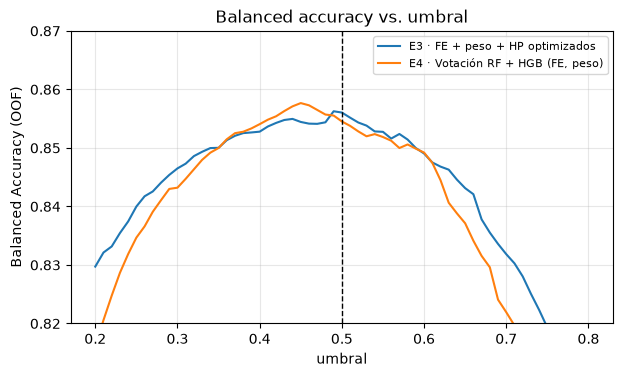

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
grilla = np.arange(0.2, 0.801, 0.01)
umbrales = {}
for nombre in ["E3 · FE + peso + HP optimizados", "E4 · Votación RF + HGB (FE, peso)"]:
    p = probas[nombre]
    ax.plot(grilla, [balanced_accuracy_score(y_train, p >= t) for t in grilla], label=nombre)
    umbrales[nombre] = C.mejor_umbral(y_train, p)
    print(f"{nombre}: umbral óptimo = {umbrales[nombre][0]:.2f} -> BA = {umbrales[nombre][1]:.4f} "
          f"(con 0.5: {balanced_accuracy_score(y_train, p >= .5):.4f})")
ax.axvline(0.5, c="k", ls="--", lw=1); ax.set_xlabel("umbral"); ax.set_ylabel("Balanced Accuracy (OOF)")
ax.set_ylim(0.82, 0.87); ax.legend(fontsize=8); ax.set_title("Balanced accuracy vs. umbral")
C.guardar(fig, "12_umbral.png"); plt.show()
nombre_e3 = "E3 · FE + peso + HP optimizados"
th_e3 = umbrales[nombre_e3][0]
p = probas[nombre_e3]
resultados["E5 · E3 + umbral óptimo"] = {
    "BA": balanced_accuracy_score(y_train, p >= th_e3), "AUC": roc_auc_score(y_train, p),
    "BA_cloud_mkt": balanced_accuracy_score(y_train[es_cm], p[es_cm] >= th_e3),
    "BA_resto": balanced_accuracy_score(y_train[~es_cm], p[~es_cm] >= th_e3), "seg": 0}

## E6 · Memoria de reservas ya vistas (vecino exacto)

En el paso 1 vimos que el 33 % de las filas son copias exactas y que **el 99 % de los lotes tiene la misma etiqueta**. Si el set de evaluación proviene de la misma fuente (mismo período, mismo sistema de reservas), es esperable que contenga reservas **idénticas** a alguna de train. Para esas reservas, la mejor predicción es la etiqueta observada: es un **vecino más cercano con distancia 0** (métodos basados en vecinos, clase 12).

La regla: si la firma (las 28 variables) de una reserva existe en train → se predice la tasa de cancelación observada para esa firma; si no → se usa el modelo.

Esta estrategia **no se puede medir con la CV por grupos** (por diseño ahí nunca hay reservas repetidas entre train y validación: daría exactamente lo mismo que el modelo). Se evalúa con la **CV aleatoria por filas**, que simula un test extraído al azar de la misma fuente, separando reservas *vistas* y *no vistas*.

In [8]:
def cv_con_memoria(fabrica, X, peso=None):
    cv = C.crear_cv("aleatorio")
    p_mod, p_mem, vista = np.zeros(len(y_train)), np.zeros(len(y_train)), np.zeros(len(y_train), bool)
    for tr, va in cv.split(X, y_train):
        memoria = pd.Series(y_train.values[tr]).groupby(grupos[tr]).mean()
        m = pd.Series(grupos[va]).map(memoria).to_numpy()
        modelo = fabrica()
        kw = {f"{modelo.steps[-1][0]}__sample_weight": peso[tr]} if peso is not None else {}
        p = modelo.fit(X.iloc[tr], y_train.iloc[tr], **kw).predict_proba(X.iloc[va])[:, 1]
        p_mod[va] = p
        p_mem[va] = np.where(np.isnan(m), p, m)
        vista[va] = ~np.isnan(m)
    return p_mod, p_mem, vista

t = time.time()
p_mod, p_mem, vista = cv_con_memoria(lambda: hgb("FE", **HP_OPT), Xf_train, 1 / np.sqrt(tam_lote))
p_base_a, _, _ = cv_con_memoria(lambda: base["modelo"], X_train)
print(f"{time.time()-t:.0f}s | reservas de validación ya vistas en train: {vista.mean():.1%}")
filas = []
for nombre, p in [("E0 · Baseline", p_base_a), ("E3 · modelo", p_mod), ("E6 · E3 + memoria", p_mem)]:
    filas.append({"modelo": nombre,
                  "BA total": balanced_accuracy_score(y_train, p >= .5),
                  "BA vistas": balanced_accuracy_score(y_train[vista], p[vista] >= .5),
                  "BA no vistas": balanced_accuracy_score(y_train[~vista], p[~vista] >= .5),
                  "AUC": roc_auc_score(y_train, p),
                  "BA cloud_mkt": balanced_accuracy_score(y_train[es_cm], p[es_cm] >= .5)})
tabla_mem = pd.DataFrame(filas).set_index("modelo")
tabla_mem.round(4)

48s | reservas de validación ya vistas en train: 38.8%


,BA total,BA vistas,BA no vistas,AUC,BA cloud_mkt
modelo,,,,,
E0 · Baseline,0.8787,0.9754,0.7819,0.9550,0.8015
E3 · modelo,0.8799,0.9712,0.7877,0.9556,0.8035
E6 · E3 + memoria,0.8865,0.9882,0.7877,0.9615,0.8135


## Comparación de estrategias contra el baseline

,BA,ΔBA,AUC,ΔAUC,BA_cloud_mkt,ΔBA_cloud_mkt,BA_resto,ΔBA_resto
"E0 · Baseline (HGB, 28 originales)",0.8524,0.0000,0.9389,0.0000,0.7774,0.0000,0.9209,0.0000
E1 · + Feature engineering,0.8513,-0.0011,0.9376,-0.0013,0.7814,0.0040,0.9152,-0.0057
E2a · FE + peso 1/sqrt(n_lote),0.8533,0.0009,0.9404,0.0015,0.7810,0.0036,0.9188,-0.0021
E2b · FE + peso 1/n_lote,0.8523,-0.0001,0.9403,0.0014,0.7788,0.0014,0.9192,-0.0017
E3 · FE + peso + HP optimizados,0.8560,0.0037,0.9420,0.0031,0.7832,0.0058,0.9224,0.0015
"(RF solo, FE)",0.8411,-0.0113,0.9347,-0.0042,0.7632,-0.0142,0.9102,-0.0107
"E4 · Votación RF + HGB (FE, peso)",0.8545,0.0021,0.9420,0.0031,0.7834,0.0060,0.9190,-0.0019
E5 · E3 + umbral óptimo,0.8563,0.0039,0.9420,0.0031,0.7846,0.0072,0.9222,0.0013


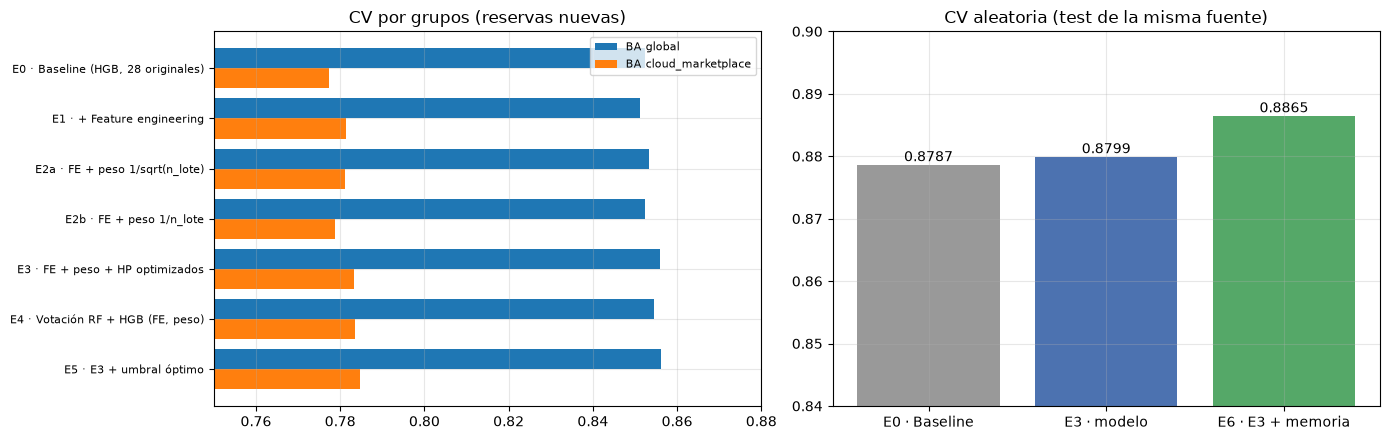

In [9]:
tabla = pd.DataFrame(resultados).T
b = tabla.loc["E0 · Baseline (HGB, 28 originales)"]
for m in ["BA", "AUC", "BA_cloud_mkt", "BA_resto"]:
    tabla[f"Δ{m}"] = tabla[m] - b[m]
display(tabla[["BA", "ΔBA", "AUC", "ΔAUC", "BA_cloud_mkt", "ΔBA_cloud_mkt", "BA_resto", "ΔBA_resto"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
t2 = tabla.drop(index="   (RF solo, FE)")
y_ = np.arange(len(t2))[::-1]
axes[0].barh(y_ + 0.2, t2["BA"], 0.4, label="BA global")
axes[0].barh(y_ - 0.2, t2["BA_cloud_mkt"], 0.4, label="BA cloud_marketplace")
axes[0].set_yticks(y_, t2.index, fontsize=8); axes[0].set_xlim(0.75, 0.88); axes[0].legend(fontsize=8)
axes[0].set_title("CV por grupos (reservas nuevas)")
axes[1].bar(tabla_mem.index, tabla_mem["BA total"], color=["#999", "#4C72B0", "#55A868"])
for i, v in enumerate(tabla_mem["BA total"]):
    axes[1].text(i, v, f"{v:.4f}", ha="center", va="bottom")
axes[1].set_ylim(0.84, 0.90); axes[1].set_title("CV aleatoria (test de la misma fuente)")
fig.tight_layout(); C.guardar(fig, "13_estrategias.png"); plt.show()

## Conclusiones del paso 4

**Resultados (CV por grupos, reservas nuevas):**

| Estrategia | ΔBA global | ΔBA cloud_mkt | ¿Se adopta? |
|---|---|---|---|
| E1 Feature engineering | −0.001 | **+0.004** | Sí (ayuda en la cohorte priorizada; habilita E2/E3) |
| E2 Peso $1/\sqrt{n_{lote}}$ | +0.001 | +0.004 | Sí ($1/n$ es demasiado agresivo) |
| E3 Hiperparámetros (RandomizedSearch) | **+0.004** | **+0.006** | Sí |
| E4 Votación RF + HGB | +0.002 | +0.006 | No: no supera a E3 a umbral 0.5, duplica el costo y RF y HGB están muy correlacionados (r = 0.96) |
| E5 Umbral óptimo (0.49) | +0.004 | +0.007 | Sí (cambio mínimo: el `class_weight="balanced"` ya dejaba el umbral cerca de 0.5) |
| E6 Memoria de reservas vistas | = (no aplica) | = | **Sí**: +0.007 en CV aleatoria (0.880 → **0.887**) |

**Lectura:**
- Sobre **reservas nuevas** las mejoras son **modestas** (0.852 → 0.856). Esto es coherente con el diagnóstico del paso 3: la curva de aprendizaje ya estaba estancada y el límite está en la **información disponible en X**, no en el modelo. Ninguna combinación de modelos o hiperparámetros supera ~0.856 con estas variables.
- **Las mejoras fueron más grandes en la cohorte priorizada** (`cloud_marketplace` +0.007) que en el resto (+0.001). El feature engineering, en particular, ayuda en `cloud_marketplace` y empeora un poco el resto. Usar ids de agente como categoría captura patrones de lote propios del marketplace.
- **La mayor ganancia viene del enfoque data-centered sobre los duplicados (E6):** en reservas ya vistas la BA pasa de 0.971 a **0.988**, sin afectar a las no vistas.
- **Modelo final elegido:** HGB + features nuevas + peso $1/\sqrt{n_{lote}}$ + hiperparámetros de E3 + umbral 0.49 + memoria de reservas vistas. Es simple, rápido de entrenar (~10 s) y sólo usa scikit-learn.

In [10]:
joblib.dump({"tabla": tabla, "tabla_mem": tabla_mem, "HP_BASE": HP_BASE, "HP_OPT": HP_OPT,
             "umbral": th_e3, "tabla_rs": tabla_rs}, C.RESULTADOS / "paso4_estrategias.joblib")

['resultados\\paso4_estrategias.joblib']